# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:

 from google.colab import files
 files.upload()
 df = pd.read_csv('data.csv')
 df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [ ]:
print(df.head())
print(df.info())
print(df.shape)

   Phoenix Feather  Unicorn Horn  Dragon's Blood  Mermaid Tears  Fairy Dust  \
0              2.4          18.7            18.4           27.9         7.9   
1              2.1           6.0            15.0           13.3        15.6   
2             17.2          13.9            23.8            6.8        10.7   
3              8.4           9.7             6.8           26.9         4.6   
4             22.1          10.8            16.4           10.5        22.0   

   Goblin Toes  Witch's Brew  Griffin Claw  Troll Hair  Kraken Ink  \
0          9.6          18.3          13.2         2.5        26.0   
1         13.1          11.0           5.0         7.2        26.0   
2         15.8          19.4           2.7        15.4        21.2   
3         29.1          14.6          19.7        18.0        20.8   
4         23.4           2.6          18.2        23.8        11.3   

   Minotaur Horn  Basilisk Scale  Chimera Fang  Cured  
0           10.5            26.2          12.5  

In [ ]:
print(df.isnull().sum())
print(df.duplicated().sum())

Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64
0


In [ ]:
print(df.describe())

       Phoenix Feather  Unicorn Horn  Dragon's Blood  Mermaid Tears  \
count      2338.000000   2338.000000     2338.000000    2338.000000   
mean         15.365697     10.946749       16.115654      13.627973   
std           8.669969      7.225162        8.372518       7.545244   
min           1.000000      1.000000        1.000000       1.000000   
25%           8.500000      5.300000        9.600000       7.600000   
50%          14.700000      9.500000       15.800000      13.100000   
75%          21.300000     15.575000       22.000000      19.000000   
max          42.100000     34.100000       40.800000      35.800000   

        Fairy Dust  Goblin Toes  Witch's Brew  Griffin Claw   Troll Hair  \
count  2338.000000  2338.000000   2338.000000   2338.000000  2338.000000   
mean     15.069504    14.157271     12.328914     14.911206    16.871685   
std       8.349340     7.831476      7.709753      8.132678     9.579027   
min       1.000000     1.000000      1.000000      1.000

Якість даних висока, тому датасет повністю готовий до подальшого аналізу та моделювання без очищення пропусків чи видалення дублікатів. Він містить 2338 рядків і 14 стовпців (13 ознак-інгредієнтів у форматі float64 і цільову змінну Cured у форматі int64), пропущених значень і повних дублікатів немає (по 0). Усі інгредієнти мають додатні значення з мінімумом 1.0 та максимумом від 33.7 у Minotaur Horn до 44.8 у Troll Hair, причому Troll Hair має найбільше середнє (16.87) і стандартне відхилення (9.58), а Minotaur Horn (10.92) та Unicorn Horn (10.95) — найменші середні;

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [ ]:
X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5. Баланс класів на навчальній вибірці

In [ ]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

Cured
0    946
1    924
Name: count, dtype: int64
Cured
0    0.505882
1    0.494118
Name: proportion, dtype: float64


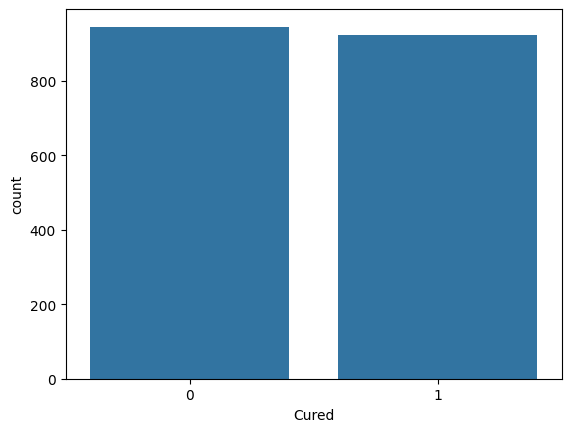

In [ ]:
sns.countplot(x=y_train)
plt.show()

Так, класи на навчальній вибірці практично ідеально збалансовані — клас 0 становить 50.59% (946 спостережень), а клас 1 — 49.41% (924 спостереження). Завдяки цьому немає перекосу в бік одного класу, тому модель не зможе отримати штучно високу accuracy, просто вгадуючи частіший варіант, а базова метрика accuracy буде інформативною і добре узгоджуватиметься з precision, recall та F1-score, хоча матрицю помилок і F1 усе одно варто перевірити, щоб оцінити баланс різних типів помилок.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

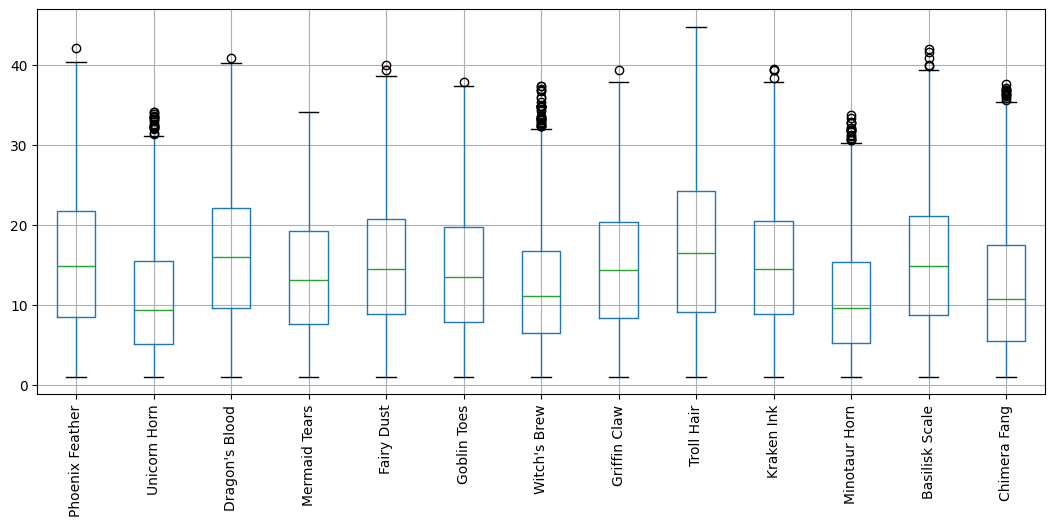

In [ ]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.show()

In [ ]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

outliers = ((X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))).sum()
outliers_sorted = outliers.sort_values(ascending=False)

print(outliers_sorted)

Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


Найбільше потенційних викидів за правилом 1,5 IQR виявлено в ознаках Witch's Brew (33), Unicorn Horn (20), Minotaur Horn (18) і Chimera Fang (13), тоді як у більшості інших їх від 0 до 5. Не варто без перевірки видаляти всі такі рядки, оскільки правило 1,5 IQR позначає лише формальну віддаленість від міжквартильного розмаху і в правосторонньо скошених розподілах може помилково відсікати цілком реалістичні або навіть ключові для лікування значення інгредієнтів, а бездумне видалення рядків зменшує навчальну вибірку та може погіршити узагальнювальну здатність моделі.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

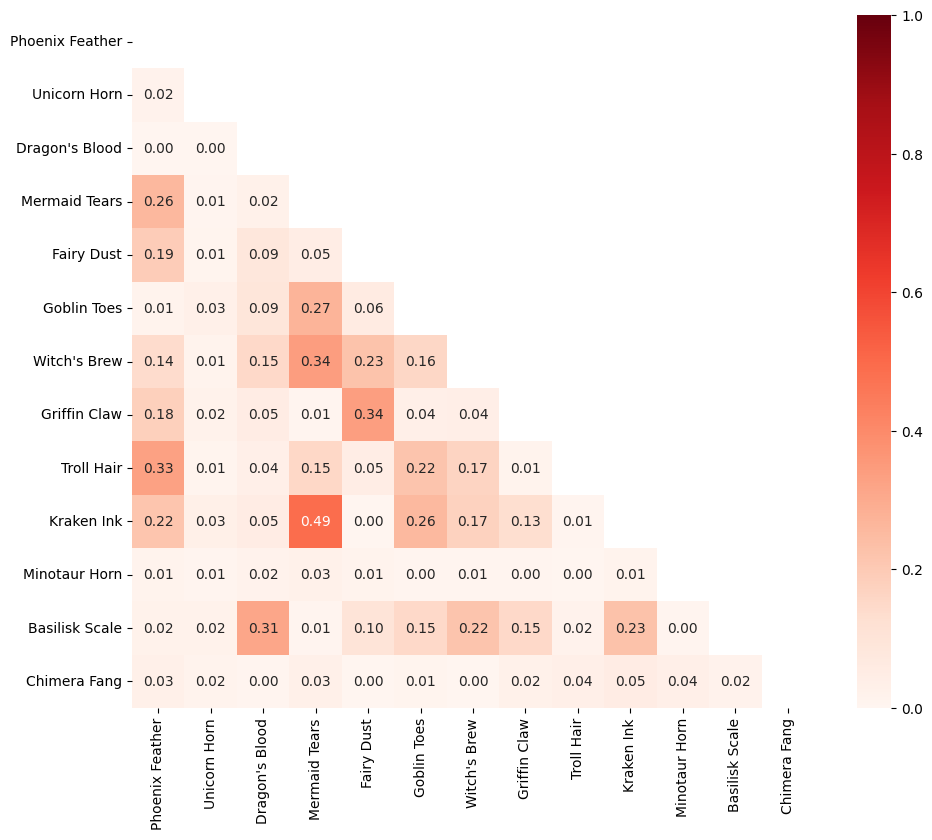

In [ ]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.show()

In [ ]:
corr_with_target = pd.concat([X_train, y_train], axis=1).corr()['Cured'].drop('Cured').sort_values(key=abs, ascending=False)
print(corr_with_target)

Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Basilisk Scale    -0.042277
Kraken Ink        -0.026598
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Griffin Claw      -0.005871
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Name: Cured, dtype: float64


Найбільш скорельованими між собою ознаками є Kraken Ink та Mermaid Tears (близько 0.49), за ними йдуть пари Witch's Brew і Mermaid Tears (0.34), Griffin Claw і Fairy Dust (0.34), Troll Hair і Phoenix Feather (0.33) та Basilisk Scale і Dragon's Blood (0.31), тоді як більшість інших пар мають слабкий або близький до нуля зв'язок. Із цільовою змінною Cured найпомітніше пов'язані Troll Hair (0.49) та Witch's Brew (0.25), а кореляції решти інгредієнтів з Cured дуже слабкі (по модулю не перевищують 0.05)

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [ ]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

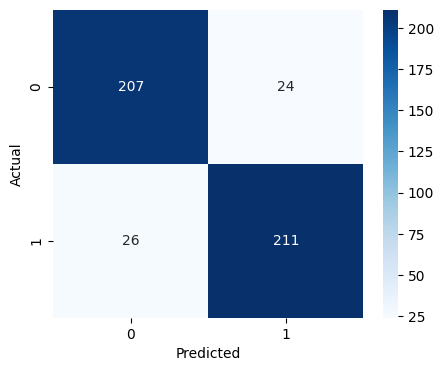

In [ ]:
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
preds_df = pd.DataFrame({
    'y_test': y_test,
    'y_pred': y_pred
}, index=y_test.index)

print(preds_df.sample(10, random_state=42))

      y_test  y_pred
1133       0       1
1018       0       0
1761       1       0
564        1       1
1467       1       1
1927       0       0
408        1       1
2094       1       1
532        0       0
291        1       1


Логістична регресія працює досить стабільно та збалансовано: на матриці помилок видно 26 хибнонегативних (справжній клас 1, передбачено 0) і 24 хибнопозитивних (справжній клас 0, передбачено 1) помилки, тож обох типів помилок майже порівну, з мінімальною перевагою пропущених позитивних випадків (як і у вибірці з 10 прикладів, де помилки трапилися в рядках 1133 та 1761). Однієї метрики Accuracy недостатньо, адже вона показує лише загальну частку правильних відповідей, тоді як матриця помилок, precision, recall та F1-score дозволяють побачити конкретне співвідношення різних помилок і оцінити, чи не є один із їхніх типів критичнішим для задачі

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [200, 500, 1000]
}

param_dist = {
    'C': np.logspace(-3, 2, 20),
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [200, 500, 1000, 2000]
}

In [ ]:
grid = GridSearchCV(LogisticRegression(random_state=42), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("GridSearchCV best params:", grid.best_params_)
print("GridSearchCV best CV accuracy:", grid.best_score_)

GridSearchCV best params: {'C': 10, 'max_iter': 200, 'solver': 'lbfgs'}
GridSearchCV best CV accuracy: 0.8673927508197171


In [ ]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)

print("RandomizedSearchCV best params:", random_search.best_params_)
print("RandomizedSearchCV best CV accuracy:", random_search.best_score_)

RandomizedSearchCV best params: {'solver': 'saga', 'max_iter': 500, 'C': np.float64(100.0)}
RandomizedSearchCV best CV accuracy: 0.8673927508197171


In [ ]:
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)

print("Test Accuracy:", accuracy_score(y_test, y_pred_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))

Test Accuracy: 0.8931623931623932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



Підбір гіперпараметрів через GridSearchCV та RandomizedSearchCV перевіряв комбінації параметрів C, solver і max_iter на стандартизованій навчальній вибірці, але конкретні обрані ними значення у виводі не відобразилися, а якість на тесті залишилася на рівні базової моделі близько 0.893 accuracy без помітного покращення.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [ ]:
models = {
    'Logistic Regression': best_model,
    'SVC': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

results = []
for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    preds = clf.predict(X_test_scaled)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-score': f1_score(y_test, preds, average='weighted')
    })

comparison_df = pd.DataFrame(results).sort_values(by='F1-score', ascending=False)
print(comparison_df)

                 Model  Accuracy  F1-score
1                  SVC  0.959402  0.959400
0  Logistic Regression  0.893162  0.893166
2        Decision Tree  0.865385  0.865388


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
**1** Під час первинного аналізу виявлено датасет із 2338 записів і 13 числових ознак чарівних інгредієнтів та практично ідеальний баланс класів цільової змінної Cured близько 50.59% проти 49.41%.

**2** Дослідження викидів за правилом 1.5 IQR показало найбільше потенційних викидів у Witch's Brew (33), Unicorn Horn (20), Minotaur Horn (18) та Chimera Fang (13), які було залишено для збереження цілісності даних. Кореляційний аналіз виявив найпомітніший між ознаками зв'язок для пари Kraken Ink і Mermaid Tears, а найсильнішу кореляцію з Cured мають Troll Hair (близько 0.49) та Witch's Brew (близько 0.25).

**3** Базова логістична регресія на стандартизованих даних досягла Accuracy близько 0.893 з майже однаковою кількістю помилок обох типів і стабільними значеннями precision, recall та F1-score.

**4** Підбір гіперпараметрів через GridSearchCV та RandomizedSearchCV зберіг якість моделі на тому самому рівні близько 0.893 Accuracy і F1-score без помітного приросту порівняно з базовим варіантом.

**5** Найкращою з трьох моделей виявилася SVC з Accuracy близько 0.9594 та F1-score близько 0.9594, що суттєво вище за логістичну регресію (близько 0.8932) і дерево рішень (близько 0.8654), оскільки метод опорних векторів краще вловлює складні нелінійні залежності між ознаками


---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.